In [7]:
# ====================== 1. Cài đặt ======================
!pip install -q stable-baselines3 gymnasium tqdm

# ====================== 2. Environment (Cải tiến mạnh động lực di chuyển) ======================
import gymnasium as gym
from gymnasium import spaces
import numpy as np

class ObstacleAvoidanceEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self):
        super().__init__()
        self.world_size = 10.0
        self.robot_radius = 0.3
        self.goal_radius = 0.5
        self.max_speed = 1.2
        self.dt = 0.1
        self.num_obstacles = 4

        self.action_space = spaces.Box(
            low=-self.max_speed, high=self.max_speed, shape=(2,), dtype=np.float32
        )
        obs_dim = 4 + self.num_obstacles * 2
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32
        )

        self.obstacles = np.array([
            [3.0, 3.5],
            [6.5, 2.5],
            [4.0, 7.0],
            [7.5, 6.5]
        ], dtype=np.float32)
        self.obstacle_radius = 0.7

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.robot_pos = np.array([1.2, 1.2], dtype=np.float32)
        self.goal_pos = np.array([8.8, 8.8], dtype=np.float32)
        return self._get_obs(), {}

    def _get_obs(self):
        return np.concatenate([
            self.robot_pos,
            self.goal_pos,
            self.obstacles.flatten()
        ]).astype(np.float32)

    def step(self, action):
        action = np.clip(action, -self.max_speed, self.max_speed)
        old_dist = np.linalg.norm(self.robot_pos - self.goal_pos)

        self.robot_pos += action * self.dt
        self.robot_pos = np.clip(self.robot_pos, 0.3, self.world_size - 0.3)

        dist_to_goal = np.linalg.norm(self.robot_pos - self.goal_pos)
        collided = any(
            np.linalg.norm(self.robot_pos - obs) < (self.robot_radius + self.obstacle_radius)
            for obs in self.obstacles
        )

        reward = 0.0
        terminated = False

        if collided:
            reward = -150.0  # Phạt va chạm rất nặng
            terminated = True
        elif dist_to_goal < self.goal_radius:
            reward = 200.0   # Thưởng cực lớn khi về đích
            terminated = True
        else:
            # Thưởng dựa trên việc "tiến lại gần đích" (hiệu khoảng cách cũ - mới)
            progress = old_dist - dist_to_goal
            # Phạt nhẹ chi phí thời gian (-0.1 mỗi bước) cộng thêm thưởng nếu tiến gần đích hơn
            reward = (progress * 15.0) - 0.1

        return self._get_obs(), reward, terminated, False, {
            "dist_to_goal": float(dist_to_goal),
            "collided": collided,
            "robot": self.robot_pos.tolist(),
            "goal": self.goal_pos.tolist(),
            "obstacles": self.obstacles.tolist()
        }

# ====================== 3. Train PPO ======================
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

print("Đang tạo environment...")
env = make_vec_env(ObstacleAvoidanceEnv, n_envs=4)

print("Bắt đầu train PPO với 100k steps (Tối ưu tiến tới đích)... ")
model = PPO(
    "MlpPolicy",
    env,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    verbose=1,
    device="auto"
)

TOTAL_TIMESTEPS = 100_000
model.learn(total_timesteps=TOTAL_TIMESTEPS, progress_bar=True)

# ====================== 4. Lưu và Tải model về ======================
MODEL_NAME = "obstacle_ppo_colab"
model.save(MODEL_NAME)
print(f"\nĐã lưu model: {MODEL_NAME}.zip")

from google.colab import files
try:
    files.download(f"{MODEL_NAME}.zip")
    print("Đã tự động tải file xuống máy của bạn.")
except Exception as e:
    print(f"Không thể tự động tải: {e}. Bạn có thể tải thủ công file {MODEL_NAME}.zip ở mục Files bên trái.")

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

Đang tạo environment...
Bắt đầu train PPO với 100k steps (Tối ưu tiến tới đích)... 
Using cpu device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 427      |
|    ep_rew_mean     | -164     |
| time/              |          |
|    fps             | 3410     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 4096     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 524         |
|    ep_rew_mean          | -166        |
| time/                   |             |
|    fps                  | 1706        |
|    iterations           | 2           |
|    time_elapsed         | 4           |
|    total_timesteps      | 8192        |
| train/                  |             |
|    approx_kl            | 0.011309214 |
|    clip_fraction        | 0.135       |
|    clip_range           | 0.2         |
|    entropy_


Đã lưu model: obstacle_ppo_colab.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Đã tự động tải file xuống máy của bạn.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

# ====================== 7. Hàm so sánh hiệu suất các mô hình ======================
def compare_models(model_paths=["obstacle_ppo_colab"], model_labels=["PPO 120k Steps (Tối ưu)"], num_episodes=50):
    env = ObstacleAvoidanceEnv()
    results = {}

    # Thêm một mô hình chưa train (Random Agent) để làm mốc so sánh gốc (Baseline)
    all_paths = [None] + model_paths
    all_labels = ["Chưa huấn luyện (Random)"] + model_labels

    for path, label in zip(all_paths, all_labels):
        success_count = 0
        collision_count = 0
        timeout_count = 0
        total_steps = []
        total_rewards = []

        # Load model nếu có
        model = PPO.load(path) if path is not None else None

        for ep in range(num_episodes):
            obs, info = env.reset()
            done = False
            ep_reward = 0
            steps = 0

            while not done and steps < 200:
                if model is not None:
                    action, _ = model.predict(obs, deterministic=True)
                else:
                    action = env.action_space.sample() # Hành động ngẫu nhiên

                obs, reward, terminated, truncated, info = env.step(action)
                ep_reward += reward
                steps += 1

                if terminated:
                    if info.get("collided", False):
                        collision_count += 1
                    elif info.get("dist_to_goal", 99) < env.goal_radius:
                        success_count += 1
                    done = True

            if not terminated and steps >= 200:
                timeout_count += 1

            total_steps.append(steps)
            total_rewards.append(ep_reward)

        results[label] = {
            "Tỷ lệ thành công (%)": (success_count / num_episodes) * 100,
            "Tỷ lệ va chạm (%)": (collision_count / num_episodes) * 100,
            "Số bước trung bình": np.mean(total_steps),
            "Phần thưởng trung bình": np.mean(total_rewards)
        }

    # --- In bảng chỉ số so sánh ---
    print(f"=== BẢNG SO SÁNH CHỈ SỐ (Đánh giá qua {num_episodes} lượt chạy) ===\n")
    header = f"{'Mô hình':<30} | {'Thành công (%)':<16} | {'Va chạm (%)':<14} | {'Số bước TB':<12} | {'Reward TB':<12}"
    print(header)
    print("-" * len(header))
    for label, metrics in results.items():
        print(f"{label:<30} | {metrics['Tỷ lệ thành công (%)']:<16.1f} | {metrics['Tỷ lệ va chạm (%)']:<14.1f} | {metrics['Số bước trung bình']:<12.1f} | {metrics['Phần thưởng trung bình']:<12.1f}")

compare_models()

=== BẢNG SO SÁNH CHỈ SỐ (Đánh giá qua 50 lượt chạy) ===

Mô hình                        | Thành công (%)   | Va chạm (%)    | Số bước TB   | Reward TB   
------------------------------------------------------------------------------------------------
Chưa huấn luyện (Random)       | 0.0              | 4.0            | 198.8        | -21.9       
PPO 120k Steps (Tối ưu)        | 100.0            | 0.0            | 113.0        | 341.5       


--- KẾT QUẢ CHẠY THỬ NGHIỆM ---
Số bước di chuyển: 12
Trạng thái: THẤT BẠI! Robot đã va chạm chướng ngại vật. 💥


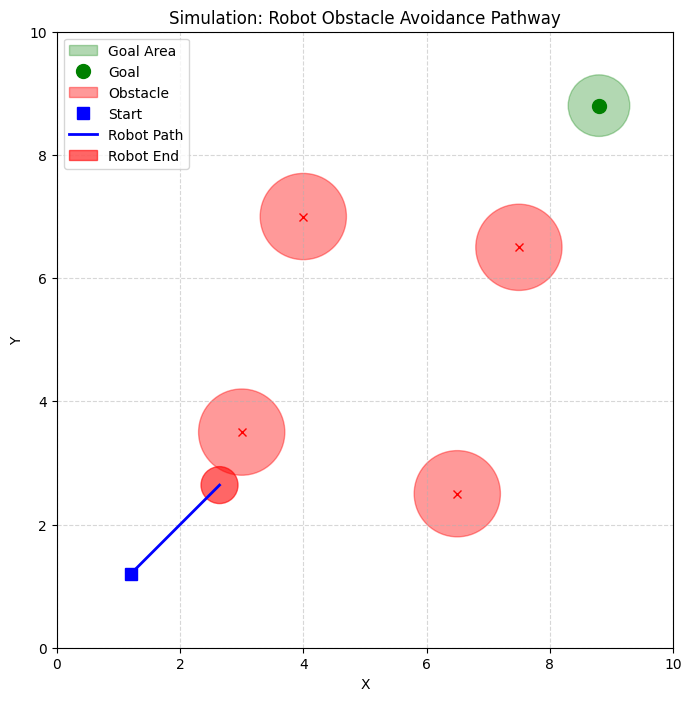

In [2]:
import matplotlib.pyplot as plt

# ====================== 6. Đánh giá và Trực quan hóa ======================
def evaluate_and_plot(model_path="obstacle_ppo_colab"):
    # Khởi tạo môi trường đơn (không vector hóa để dễ tracking)
    test_env = ObstacleAvoidanceEnv()
    obs, info = test_env.reset()

    # Load model đã train
    trained_model = PPO.load(model_path)

    robot_path = [test_env.robot_pos.copy()]
    done = False
    step_count = 0
    max_steps = 200
    collided = False
    success = False

    while not done and step_count < max_steps:
        # Dự đoán hành động từ model
        action, _states = trained_model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = test_env.step(action)

        robot_path.append(test_env.robot_pos.copy())
        step_count += 1

        if terminated:
            if info.get("collided", False):
                collided = True
            elif info.get("dist_to_goal", 99) < test_env.goal_radius:
                success = True
            done = True

    robot_path = np.array(robot_path)

    # --- In kết quả đánh giá ---
    print("--- KẾT QUẢ CHẠY THỬ NGHIỆM ---")
    print(f"Số bước di chuyển: {step_count}")
    if success:
        print("Trạng thái: THÀNH CÔNG! Robot đã chạm đích. 🎉")
    elif collided:
        print("Trạng thái: THẤT BẠI! Robot đã va chạm chướng ngại vật. 💥")
    else:
        print("Trạng thái: THẤT BẠI! Hết thời gian (Quá số bước quy định).")

    # --- Vẽ giao diện đường đi ---
    fig, ax = plt.subplots(figsize=(8, 8))

    # Vẽ biên bản đồ
    ax.set_xlim(0, test_env.world_size)
    ax.set_ylim(0, test_env.world_size)
    ax.set_aspect('equal')
    ax.grid(True, linestyle='--', alpha=0.5)

    # Vẽ Goal (Điểm đích)
    goal_circle = plt.Circle(test_env.goal_pos, test_env.goal_radius, color='green', alpha=0.3, label='Goal Area')
    ax.add_patch(goal_circle)
    ax.plot(test_env.goal_pos[0], test_env.goal_pos[1], 'go', markersize=10, label='Goal')

    # Vẽ Obstacles (Các chướng ngại vật)
    for i, obs_pos in enumerate(test_env.obstacles):
        obs_circle = plt.Circle(obs_pos, test_env.obstacle_radius, color='red', alpha=0.4, label='Obstacle' if i==0 else "")
        ax.add_patch(obs_circle)
        ax.plot(obs_pos[0], obs_pos[1], 'rx')

    # Vẽ Robot xuất phát
    start_pos = robot_path[0]
    ax.plot(start_pos[0], start_pos[1], 'bs', markersize=8, label='Start')

    # Vẽ đường đi của Robot
    ax.plot(robot_path[:, 0], robot_path[:, 1], 'b-', linewidth=2, label='Robot Path')

    # Vẽ vị trí cuối cùng của Robot
    end_color = 'g' if success else ('r' if collided else 'y')
    end_circle = plt.Circle(robot_path[-1], test_env.robot_radius, color=end_color, alpha=0.6, label='Robot End')
    ax.add_patch(end_circle)

    plt.title("Simulation: Robot Obstacle Avoidance Pathway")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend(loc='upper left')
    plt.show()

evaluate_and_plot()

In [15]:
# 1. Cài đặt MuJoCo, các thư viện dựng hình headless và hỗ trợ render video trong Colab
!apt-get update -y -q
!apt-get install -y -q libosmesa6-dev patchelf
!pip install -q mujoco imageio imageio-ffmpeg gymnasium

Get:1 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:9 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,420 kB]
Get:10 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,132 kB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,551 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-backports InRelease

In [21]:
import numpy as np
from stable_baselines3 import PPO

# 1. Chạy mô phỏng bằng Model PPO đã train ngay tại tiến trình chính để lưu lại tọa độ hành trình
env = ObstacleAvoidanceEnv()
obs, info = env.reset()
trained_model = PPO.load("obstacle_ppo_colab")

# Lưu trữ toàn bộ tọa độ robot đi qua
trajectory = [env.robot_pos.copy().tolist()]
done = False
step = 0

while not done and step < 200:
    action, _ = trained_model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    trajectory.append(env.robot_pos.copy().tolist())
    step += 1
    if terminated:
        break

print(f"Đã thu thập xong {len(trajectory)} bước hành trình từ mô hình PPO thành công!")

# 2. Ghi danh sách tọa độ này vào file script để MuJoCo đọc và tái hiện 3D độc lập (không cần import PyTorch)
import json
with open("trajectory.json", "w") as f:
    json.dump(trajectory, f)

with open("run_simulation.py", "w") as f:
    f.write("""
import os
os.environ["MUJOCO_GL"] = "osmesa"

import mujoco
import numpy as np
import imageio
import json

# Tải tọa độ hành trình
with open("trajectory.json", "r") as f:
    trajectory = json.load(f)

# Khởi tạo XML MuJoCo
xml_model = \"\"\"
<mujoco model=\"obstacle_avoidance\">
    <option timestep=\"0.05\" gravity=\"0 0 -9.81\"/>
    <worldbody>
        <geom name=\"floor\" type=\"plane\" pos=\"5 5 0\" size=\"5 5 0.1\" rgba=\"0.8 0.8 0.8 1\"/>
        <site name=\"goal\" type=\"cylinder\" pos=\"8.8 8.8 0.01\" size=\"0.5 0.01\" rgba=\"0 1 0 0.5\"/>
        <geom name=\"obs1\" type=\"cylinder\" pos=\"3.0 3.5 0.5\" size=\"0.7 0.5\" rgba=\"1 0 0 0.7\"/>
        <geom name=\"obs2\" type=\"cylinder\" pos=\"6.5 2.5 0.5\" size=\"0.7 0.5\" rgba=\"1 0 0 0.7\"/>
        <geom name=\"obs3\" type=\"cylinder\" pos=\"4.0 7.0 0.5\" size=\"0.7 0.5\" rgba=\"1 0 0 0.7\"/>
        <geom name=\"obs4\" type=\"cylinder\" pos=\"7.5 6.5 0.5\" size=\"0.7 0.5\" rgba=\"1 0 0 0.7\"/>
        <body name=\"robot\" pos=\"1.2 1.2 0.3\">
            <joint name=\"slider_x\" type=\"slide\" axis=\"1 0 0\"/>
            <joint name=\"slider_y\" type=\"slide\" axis=\"0 1 0\"/>
            <geom name=\"robot_geom\" type=\"sphere\" size=\"0.3\" rgba=\"0 0.5 1 1\"/>
        </body>
    </worldbody>
</mujoco>
\"\"\"

model = mujoco.MjModel.from_xml_string(xml_model)
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model, width=640, height=480)

# Thiết lập camera
camera = mujoco.MjvCamera()
camera.lookat = np.array([5.0, 5.0, 0.0])
camera.distance = 13.0
camera.elevation = -60.0
camera.azimuth = 45.0

frames = []

print("Đang sinh các khung hình 3D từ dữ liệu hành trình...")
for pos in trajectory:
    # Đưa tọa độ XY trực tiếp vào khớp trượt của robot trong MuJoCo
    data.qpos[0] = pos[0] - 1.2
    data.qpos[1] = pos[1] - 1.2

    # Cập nhật trạng thái vật lý
    mujoco.mj_forward(model, data)

    # Render
    renderer.update_scene(data, camera=camera)
    frame = renderer.render()
    frames.append(frame)

# Lưu video
imageio.mimsave("mujoco_simulation.mp4", frames, fps=20)
print("Đã xuất video mô phỏng 3D thành công!")
""")

# Chạy script render riêng biệt cực nhẹ
!python run_simulation.py

Đã thu thập xong 114 bước hành trình từ mô hình PPO thành công!
Đang sinh các khung hình 3D từ dữ liệu hành trình...
Đã xuất video mô phỏng 3D thành công!


In [22]:
# 3. Hiển thị trực tiếp video chuyển động trong Colab
import os
from IPython.display import HTML
from base64 import b64encode

if os.path.exists('mujoco_simulation.mp4'):
    mp4 = open('mujoco_simulation.mp4','rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""
    <video width="640" height="480" controls autoplay loop>
          <source src="{data_url}" type="video/mp4">
    </video>
    """))
else:
    print("Chưa tìm thấy file video. Hãy đảm bảo cell mô phỏng phía trên đã chạy thành công!")